# Omnichannel HCP Engagement: What Promotion Reaches, What It Moves, and What to Send Next

**Questions:**
1. How do diabetes and obesity brands actually spend their personal-promotion
   budget on prescribers, and does it reach the right ones?
2. Does promotion line up with prescribing, once like is compared with like?
3. Across all channels, which attribution and targeting methods get the right
   answer, and can a learning system choose the next best channel?

**Data:**
- **CMS Open Payments 2022–2024 (real):** every meal, speaker fee, consulting
  fee and travel payment that manufacturers reported making to US prescribers
  for GLP-1, SGLT2 and DPP-4 brands, about 1.1 million records a year.
  Open Payments is the US Sunshine Act database; reporting is mandatory.
- **Medicare Part D prescribers 2022–2024 (real):** claims by prescriber and
  brand, from project 01.
- **Simulated omnichannel journeys (`journeys.py`):** rep visits, emails,
  webinars, speaker programmes and digital ads are not public, so parts 4–7
  use a simulation of 20,000 prescribers with a known true effect for every
  channel, which lets every method be checked against the answer.

**Terms:**
- **HCP:** healthcare professional who can prescribe (physicians, nurse practitioners, physician assistants).
- **Reach / frequency:** share of target HCPs touched at least once, and how often.
- **Share of voice (SOV) vs share of market (SOM):** a brand's share of the
  class's promotion against its share of prescriptions.
- **Propensity score matching (PSM):** pair each promoted HCP with an
  unpromoted HCP who looked the same beforehand, to compare like with like.
- **Attribution:** splitting credit for a conversion across the channels that touched it.
- **Uplift:** the extra chance of adoption a channel *causes* for one prescriber.
- **Contextual bandit:** a policy that learns which action works best in
  each situation while it is running, balancing trying things against using
  what works.

In [1]:
import sys
import warnings
from itertools import combinations
from math import factorial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
HERE = Path.cwd() if Path.cwd().name.startswith("05-") else Path("05-omnichannel-hcp-engagement")
sys.path.insert(0, str(HERE.parent))
sys.path.insert(0, str(HERE))
from common import style  # noqa: E402
import journeys as J  # noqa: E402

style.apply()
RAW, FIG, TAB = HERE / "data" / "raw", HERE / "outputs" / "figures", HERE / "outputs" / "tables"
TAB.mkdir(parents=True, exist_ok=True)
PD_RAW = HERE.parent / "01-glp1-market-and-targeting" / "data" / "raw"
SRC_OP = "CMS Open Payments general payments 2022-2024; CMS Medicare Part D Prescribers by Provider and Drug"
SRC_SIM = "Simulated omnichannel journeys (journeys.py), 20,000 prescribers over 52 weeks"

op = pd.concat([pd.read_csv(RAW / f"openpayments_{y}.csv.gz", dtype={"npi": str}).assign(year=y) for y in (2022, 2023, 2024)])
op["company"] = op["manufacturer"].str.extract(r"^(Lilly|Eli Lilly|Novo Nordisk|Boehringer|AstraZeneca|Sanofi|Merck|Janssen)", expand=False)
op["company"] = op["company"].replace({"Eli Lilly": "Lilly"}).fillna("Other")
partd = {y: pd.read_csv(PD_RAW / f"prescriber_drug_{y}.csv.gz", dtype={"Prscrbr_NPI": str}) for y in (2022, 2023, 2024)}
print(f"{op['payments'].sum():,.0f} payment records, ${op['amount'].sum() / 1e6:,.0f}M, {op['npi'].nunique():,} prescribers reached, 2022-2024")

3,381,604 payment records, $166M, 231,684 prescribers reached, 2022-2024


## 1. What personal promotion looks like

Almost all payments are meals bought for the prescriber, usually during a
rep's visit or a lunch-and-learn. Speaker fees ("compensation for services
other than consulting") are few but account for half the money.

In [2]:
y24 = op[op["year"] == 2024]
nature = y24.groupby("nature")[["payments", "amount"]].sum().sort_values("payments", ascending=False)
nature["share of payments"] = nature["payments"] / nature["payments"].sum()
nature["share of dollars"] = nature["amount"] / nature["amount"].sum()
nature["average $"] = nature["amount"] / nature["payments"]
nature.index = nature.index.str.replace("Compensation for services other than consulting, including serving as faculty or as a speaker at a venue other than a continuing education program", "Speaker fees")
nature.head(6).round(3)

,payments,amount,share of payments,share of dollars,average $
nature,,,,,
Food and Beverage,1072863,23304568.96,0.971,0.428,21.722
Speaker fees,21506,27917481.26,0.019,0.513,1298.125
Travel and Lodging,8007,1644251.12,0.007,0.030,205.352
Education,2449,82913.97,0.002,0.002,33.856
Consulting Fee,454,1440102.74,0.000,0.026,3172.032


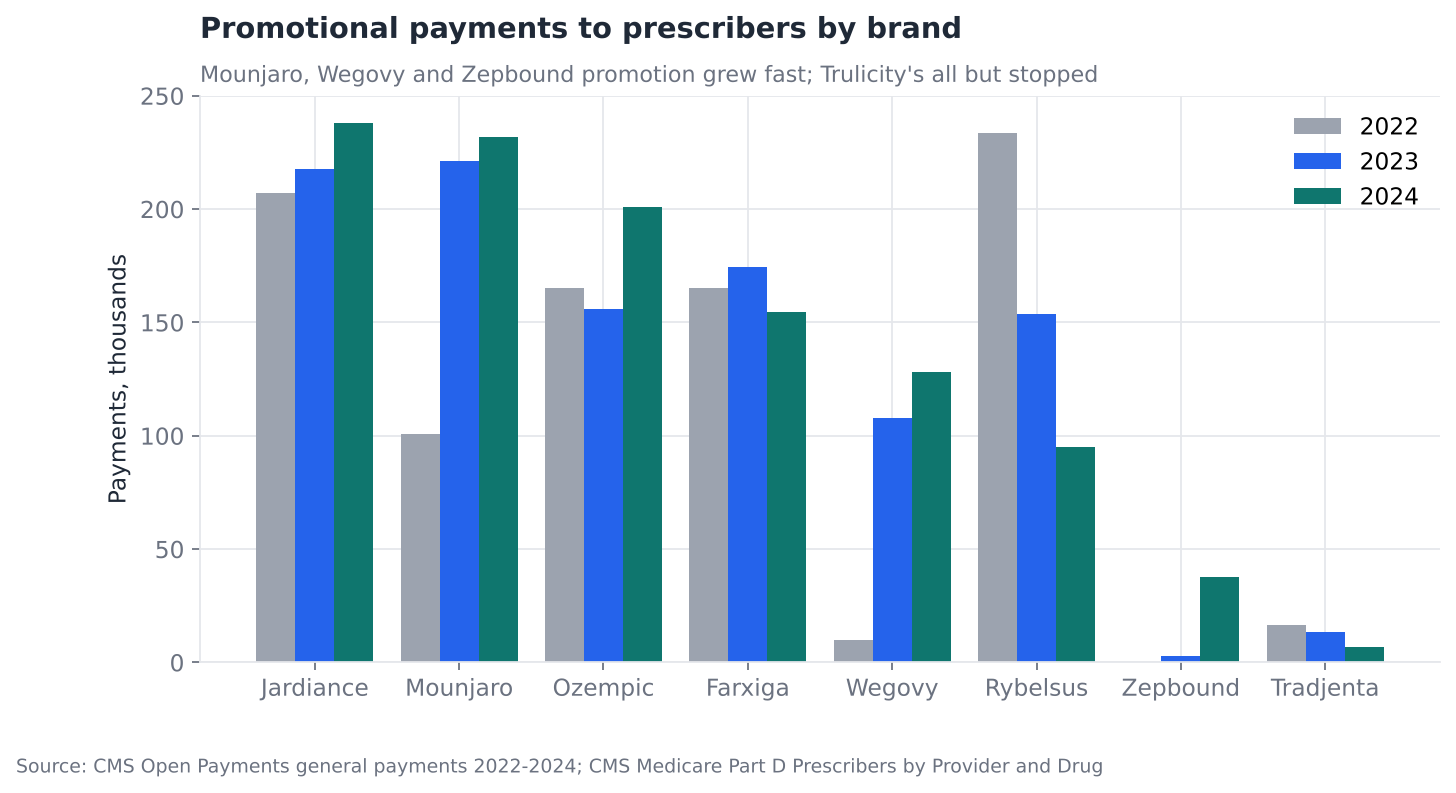

,year,company,payments,dollars,hcps
17,2024,Lilly,378083,23.4,87317
19,2024,Novo Nordisk,426710,15.6,99369
15,2024,Boehringer,145846,8.8,53532
14,2024,AstraZeneca,154451,6.5,58714
20,2024,Other,108,0.1,40


In [3]:
by_co = op.groupby(["year", "company"]).agg(payments=("payments", "sum"), dollars=("amount", "sum"), hcps=("npi", "nunique")).reset_index()
by_brand = op.groupby(["year", "brand"])["payments"].sum().unstack(0).fillna(0).sort_values(2024, ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.6))
top = by_brand.head(8)
x = np.arange(len(top))
for i, y in enumerate([2022, 2023, 2024]):
    ax.bar(x + (i - 1) * 0.27, top[y] / 1e3, 0.27, color=[style.NEUTRAL, style.PALETTE[1], style.ACCENT][i], label=str(y))
ax.set_xticks(x, top.index.str.title(), rotation=0)
ax.set_ylabel("Payments, thousands")
ax.set_title("Promotional payments to prescribers by brand")
style.subtitle(ax, "Mounjaro, Wegovy and Zepbound promotion grew fast; Trulicity's all but stopped")
ax.legend()
style.source(fig, SRC_OP)
style.save(fig, FIG / "01_payments_by_brand.png")
by_co[by_co["year"] == 2024].sort_values("dollars", ascending=False).head(5).assign(dollars=lambda d: (d["dollars"] / 1e6).round(1))

## 2. Does promotion reach the prescribers who matter?

Rank every Part D GLP-1 prescriber in 2024 into ten equal-volume groups
(deciles, 10 = the highest-volume prescribers) and measure what share of each
group Novo Nordisk and Lilly reached with at least one payment for a GLP-1
brand.

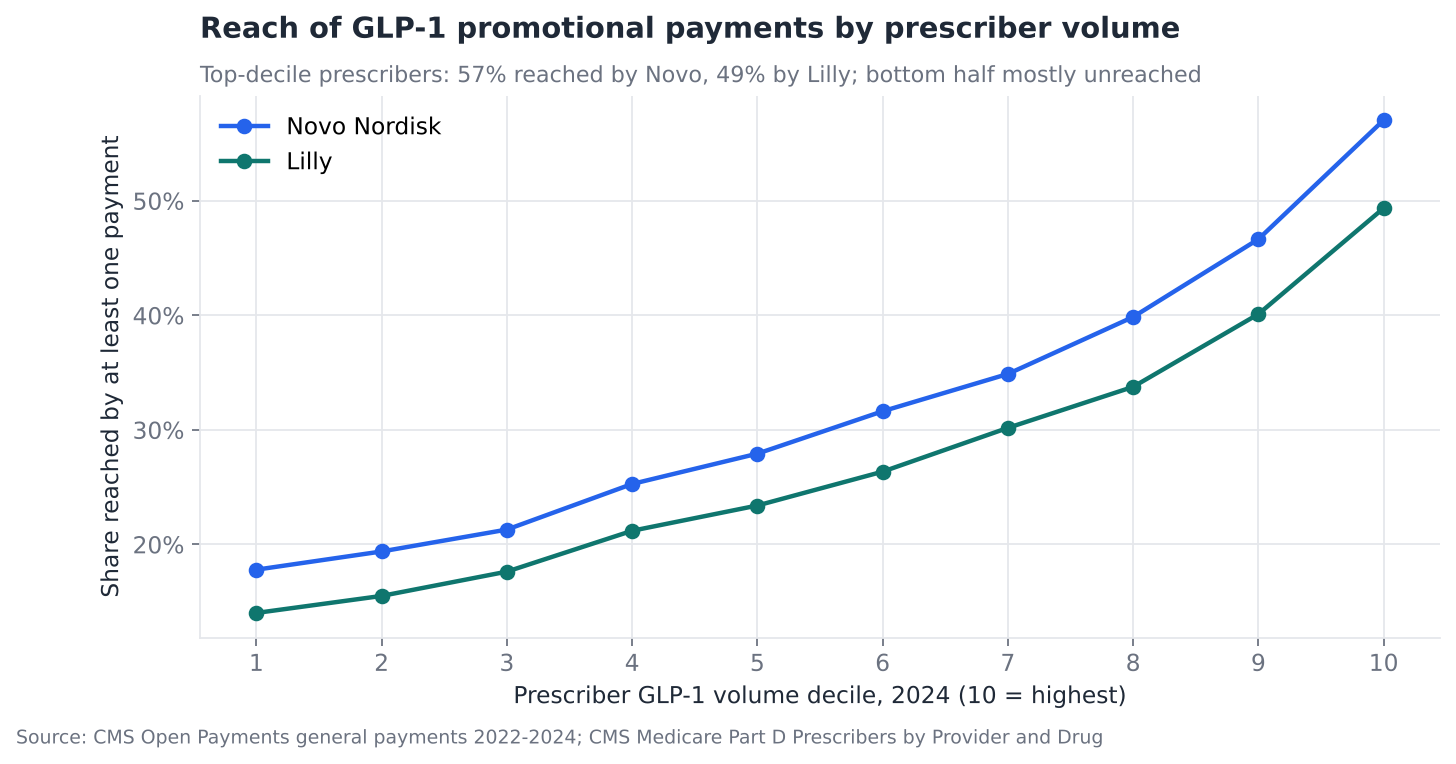

,prescribers,share of GLP-1 claims,Novo reach,Lilly reach,Novo payments per reached,Lilly payments per reached
decile,,,,,,
1,19992.0,0.012,0.178,0.140,3.537,2.692
2,19992.0,0.017,0.194,0.155,3.657,2.856
3,19992.0,0.025,0.213,0.176,3.947,2.901
4,19992.0,0.035,0.253,0.212,4.244,3.121
5,19992.0,0.049,0.279,0.234,4.449,3.311
6,19992.0,0.065,0.316,0.264,4.859,3.546
7,19992.0,0.087,0.349,0.302,5.095,3.689
8,19992.0,0.119,0.399,0.338,5.380,4.031
9,19992.0,0.174,0.466,0.401,6.062,4.440


In [4]:
g24 = partd[2024]
glp1_brands = {"Ozempic", "Rybelsus", "Victoza 2-Pak", "Victoza 3-Pak", "Wegovy", "Mounjaro", "Zepbound", "Trulicity", "Bydureon Bcise", "Byetta", "Soliqua 100-33", "Xultophy 100-3.6"}
g24 = g24[g24["Brnd_Name"].isin(glp1_brands)]
vol = g24.groupby("Prscrbr_NPI").agg(claims=("Tot_Clms", "sum"), spec=("Prscrbr_Type", "first"))
vol["decile"] = pd.qcut(vol["claims"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
glp = y24[y24["drug_class"] == "GLP-1"]
for co in ["Novo Nordisk", "Lilly"]:
    reached = glp[glp["company"] == co].groupby("npi")["payments"].sum()
    vol[f"{co} payments"] = vol.index.map(reached).fillna(0)
reach = vol.groupby("decile").apply(lambda d: pd.Series({
    "prescribers": len(d), "share of GLP-1 claims": d["claims"].sum() / vol["claims"].sum(),
    "Novo reach": (d["Novo Nordisk payments"] > 0).mean(), "Lilly reach": (d["Lilly payments"] > 0).mean(),
    "Novo payments per reached": d.loc[d["Novo Nordisk payments"] > 0, "Novo Nordisk payments"].mean(),
    "Lilly payments per reached": d.loc[d["Lilly payments"] > 0, "Lilly payments"].mean()}))

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(reach.index, reach["Novo reach"], marker="o", color=style.PALETTE[1], lw=2, label="Novo Nordisk")
ax.plot(reach.index, reach["Lilly reach"], marker="o", color=style.ACCENT, lw=2, label="Lilly")
ax.set_xticks(range(1, 11))
ax.set_xlabel("Prescriber GLP-1 volume decile, 2024 (10 = highest)")
ax.set_ylabel("Share reached by at least one payment")
style.pct(ax)
ax.set_title("Reach of GLP-1 promotional payments by prescriber volume")
style.subtitle(ax, f"Top-decile prescribers: {reach.loc[10, 'Novo reach']:.0%} reached by Novo, {reach.loc[10, 'Lilly reach']:.0%} by Lilly; "
               f"bottom half mostly unreached")
ax.legend()
style.source(fig, SRC_OP)
style.save(fig, FIG / "02_reach_by_decile.png")
reach.round(3)

Promotion is well aimed at volume: the top decile writes the most claims and
is reached most often and most frequently. But even in the top decile a large
minority are not reached at all by one of the two leaders, which is either a
coverage gap for that company or a sign those prescribers do not take meetings.
That is the group where non-personal channels (email, webinars, digital) have
to do the work.

## 3. Share of voice against share of market

For each specialty and each state, compare Lilly's share of GLP-1 promotional
payments (Lilly vs Novo) with its share of the two companies' GLP-1 claims in
Part D. Above the line, Lilly promotes more than its current share; below, less.

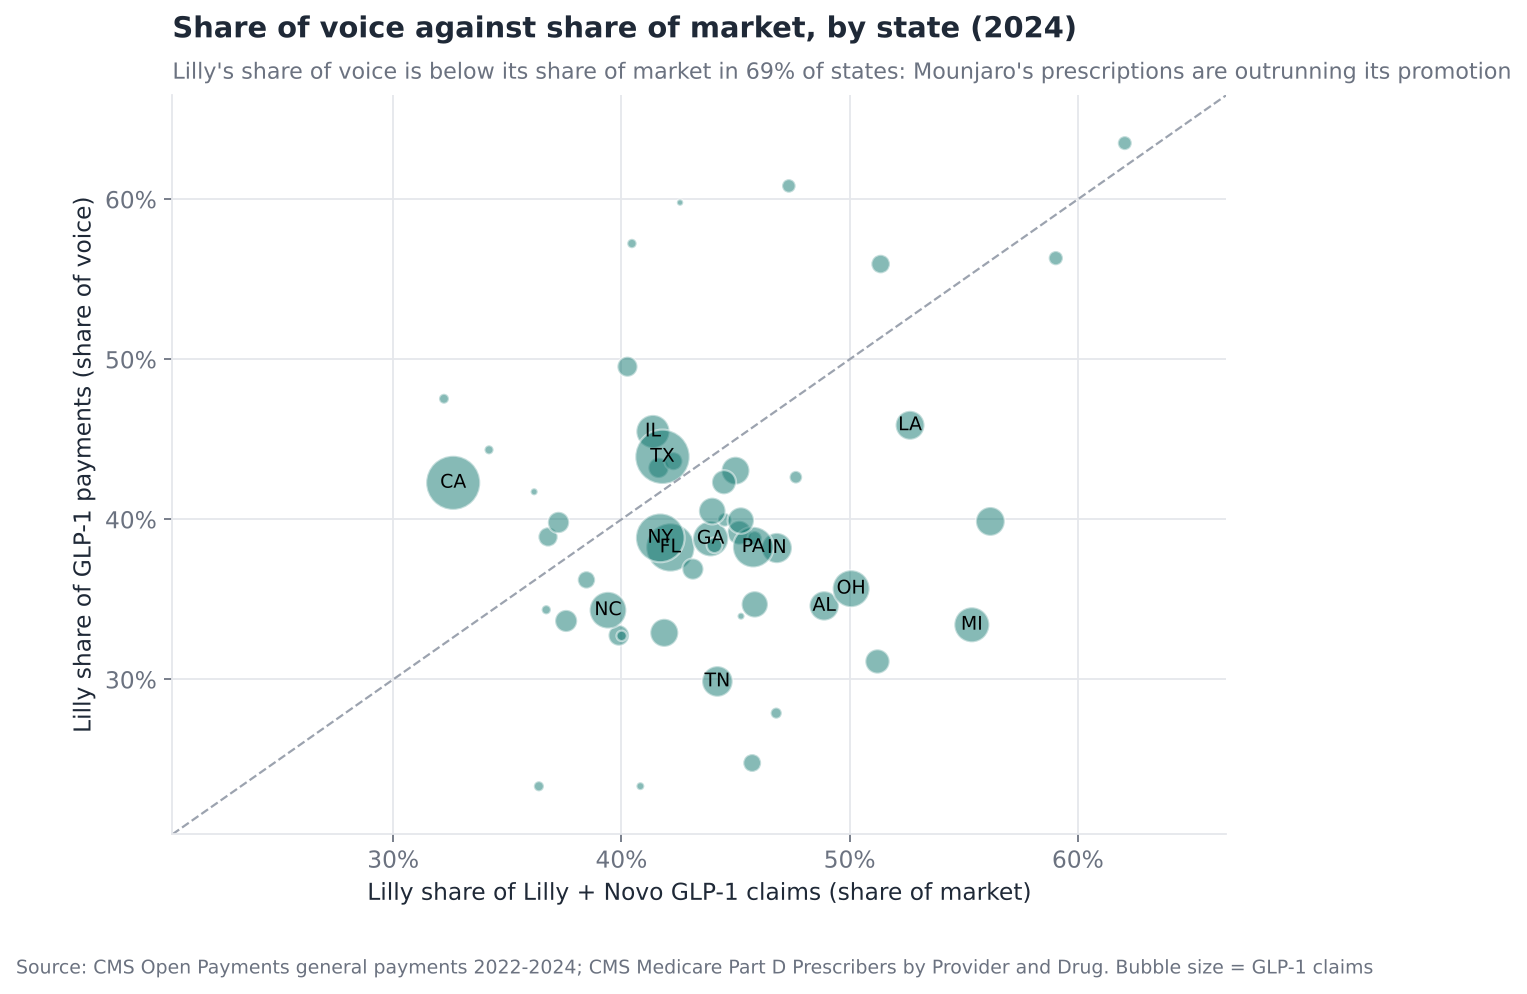

Median state: Lilly share of voice minus share of market = -4.8 points


In [5]:
lilly_b = {"Mounjaro", "Zepbound", "Trulicity"}
novo_b = {"Ozempic", "Rybelsus", "Victoza 2-Pak", "Victoza 3-Pak", "Wegovy"}
g24["co"] = np.where(g24["Brnd_Name"].isin(lilly_b), "Lilly", np.where(g24["Brnd_Name"].isin(novo_b), "Novo Nordisk", None))
som_state = g24.dropna(subset=["co"]).pivot_table(index="Prscrbr_State_Abrvtn", columns="co", values="Tot_Clms", aggfunc="sum")
sov_state = glp[glp["company"].isin(["Lilly", "Novo Nordisk"])].pivot_table(index="state", columns="company", values="payments", aggfunc="sum")
ss = pd.DataFrame({"SOM": som_state["Lilly"] / som_state.sum(axis=1), "SOV": sov_state["Lilly"] / sov_state.sum(axis=1),
                   "claims": som_state.sum(axis=1)}).dropna()
ss = ss[ss["claims"] > 20_000]
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(ss["SOM"], ss["SOV"], s=ss["claims"] / ss["claims"].max() * 600, color=style.ACCENT, alpha=0.5, edgecolor="white")
for st, r in ss.sort_values("claims", ascending=False).head(14).iterrows():
    ax.annotate(st, (r["SOM"], r["SOV"]), fontsize=8.5, ha="center", va="center")
lim = [min(ss["SOM"].min(), ss["SOV"].min()) - 0.03, max(ss["SOM"].max(), ss["SOV"].max()) + 0.03]
ax.plot(lim, lim, color=style.NEUTRAL, ls="--", lw=1)
ax.set_xlim(lim)
ax.set_ylim(lim)
style.pct(ax)
style.pct(ax, "x")
ax.set_xlabel("Lilly share of Lilly + Novo GLP-1 claims (share of market)")
ax.set_ylabel("Lilly share of GLP-1 payments (share of voice)")
ax.set_title("Share of voice against share of market, by state (2024)")
above = float((ss["SOV"] > ss["SOM"]).mean())
style.subtitle(ax, f"Lilly's share of voice is below its share of market in {1 - above:.0%} of states: Mounjaro's prescriptions are outrunning its promotion")
style.source(fig, SRC_OP + ". Bubble size = GLP-1 claims")
style.save(fig, FIG / "03_sov_vs_som.png")
sov_gap = float((ss["SOV"] - ss["SOM"]).median())
print(f"Median state: Lilly share of voice minus share of market = {sov_gap * 100:+.1f} points")

## 4. Does promotion line up with prescribing? A matched comparison

The question a brand team asks: do prescribers who start receiving Mounjaro
promotion increase Mounjaro's share of their GLP-1 prescribing more than
similar prescribers who do not?

**Design:**
- **Test group:** prescribers who received no Mounjaro-linked payment in 2022
  or 2023 and at least one in 2024 (newly reached).
- **Control pool:** prescribers who received none in any of the three years.
- **Matching:** a logistic regression predicts who gets newly reached from
  2023 behaviour (GLP-1 volume, Mounjaro share, Ozempic share, whether Novo
  promoted to them, specialty, region). Each test prescriber is paired with
  the control prescriber with the nearest score (propensity score matching).
- **Outcome:** change in Mounjaro's share of the prescriber's GLP-1 claims,
  2023 to 2024.
- **Pre-trend check:** the same comparison for 2022 to 2023, *before* the test
  group was reached. If reps simply picked prescribers who were already
  moving towards Mounjaro, it shows up here.

In [6]:
def shares(df):
    d = df[df["Brnd_Name"].isin(glp1_brands)]
    t = d.groupby("Prscrbr_NPI").agg(glp1=("Tot_Clms", "sum"), spec=("Prscrbr_Type", "first"), state=("Prscrbr_State_Abrvtn", "first"))
    t["mounjaro"] = d[d["Brnd_Name"] == "Mounjaro"].groupby("Prscrbr_NPI")["Tot_Clms"].sum()
    t["ozempic"] = d[d["Brnd_Name"] == "Ozempic"].groupby("Prscrbr_NPI")["Tot_Clms"].sum()
    t = t.fillna({"mounjaro": 0, "ozempic": 0})
    t["mj_share"] = t["mounjaro"] / t["glp1"]
    t["oz_share"] = t["ozempic"] / t["glp1"]
    return t


s22, s23, s24 = shares(partd[2022]), shares(partd[2023]), shares(partd[2024])
mj = op[op["brand"].isin(["MOUNJARO"])]
mj_years = mj.groupby("npi")["year"].agg(set)
novo23 = set(op[(op["year"] == 2023) & (op["company"] == "Novo Nordisk") & (op["drug_class"] == "GLP-1")]["npi"])
base = s23.join(s24[["glp1", "mj_share", "oz_share"]], rsuffix="_24", how="inner")
base = base[(base["glp1"] >= 20) & (base["glp1_24"] >= 20)]
yrs = base.index.map(lambda n: mj_years.get(n, set()))
base["treated"] = [1 if (s == {2024}) else 0 if not s else -1 for s in yrs]
base = base[base["treated"] >= 0].copy()
base["novo23"] = base.index.isin(novo23).astype(int)
base["ln_glp1"] = np.log(base["glp1"])
REGION = {**{s: "NE" for s in ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"]},
          **{s: "MW" for s in ["IL", "IN", "MI", "OH", "WI", "IA", "KS", "MN", "MO", "NE", "ND", "SD"]},
          **{s: "S" for s in ["DE", "FL", "GA", "MD", "NC", "SC", "VA", "DC", "WV", "AL", "KY", "MS", "TN", "AR", "LA", "OK", "TX"]}}
base["region"] = base["state"].map(REGION).fillna("W")
base["spec_g"] = base["spec"].where(base["spec"].isin(["Family Practice", "Internal Medicine", "Nurse Practitioner", "Endocrinology", "Physician Assistant"]), "Other")
Xp = pd.get_dummies(base[["ln_glp1", "mj_share", "oz_share", "novo23", "spec_g", "region"]], drop_first=True).astype(float)
ps = LogisticRegression(max_iter=2000).fit(Xp, base["treated"]).predict_proba(Xp)[:, 1]
base["ps"] = ps
tr, co_ = base[base["treated"] == 1], base[base["treated"] == 0]
nn = NearestNeighbors(n_neighbors=1).fit(co_[["ps"]])
dist, idx = nn.kneighbors(tr[["ps"]])
caliper = 0.2 * base["ps"].std()
keep = dist[:, 0] <= caliper
tr_m, co_m = tr[keep], co_.iloc[idx[keep, 0]]


def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


bal = pd.DataFrame({v: {"before matching": smd(tr[v], co_[v]), "after matching": smd(tr_m[v], co_m[v].values)}
                    for v in ["ln_glp1", "mj_share", "oz_share", "novo23"]}).T
bal

,before matching,after matching
ln_glp1,0.149792,0.086866
mj_share,0.169946,0.036266
oz_share,0.102757,-0.036923
novo23,0.932918,-0.000583


**Balance check.** The standardised mean difference (SMD) is the gap between
the groups in units of standard deviation; below 0.1 is the usual standard for
"comparable". Before matching the newly reached prescribers are much larger
and already more Novo-promoted; after matching they are comparable.

In [7]:
d_mj = (tr_m["mj_share_24"] - tr_m["mj_share"]).to_numpy() - (co_m["mj_share_24"] - co_m["mj_share"]).to_numpy()
pre_tr = s22.reindex(tr_m.index)["mj_share"].fillna(0).to_numpy()
pre_co = s22.reindex(co_m.index)["mj_share"].fillna(0).to_numpy()
d_pre = (tr_m["mj_share"].to_numpy() - pre_tr) - (co_m["mj_share"].to_numpy() - pre_co)
rng = np.random.default_rng(0)
boot = [rng.choice(d_mj, len(d_mj)).mean() for _ in range(2000)]
boot_pre = [rng.choice(d_pre, len(d_pre)).mean() for _ in range(2000)]
att = {"matched pairs": int(keep.sum()), "ATT on Mounjaro share (points)": float(d_mj.mean() * 100),
       "95% CI low": float(np.percentile(boot, 2.5) * 100), "95% CI high": float(np.percentile(boot, 97.5) * 100),
       "pre-trend 2022-23 (points)": float(d_pre.mean() * 100),
       "pre-trend CI low": float(np.percentile(boot_pre, 2.5) * 100), "pre-trend CI high": float(np.percentile(boot_pre, 97.5) * 100)}
pd.Series(att).round(2)

matched pairs                     6870.00
ATT on Mounjaro share (points)       2.37
95% CI low                           1.78
95% CI high                          2.93
pre-trend 2022-23 (points)           0.59
pre-trend CI low                     0.20
pre-trend CI high                    0.97
dtype: float64

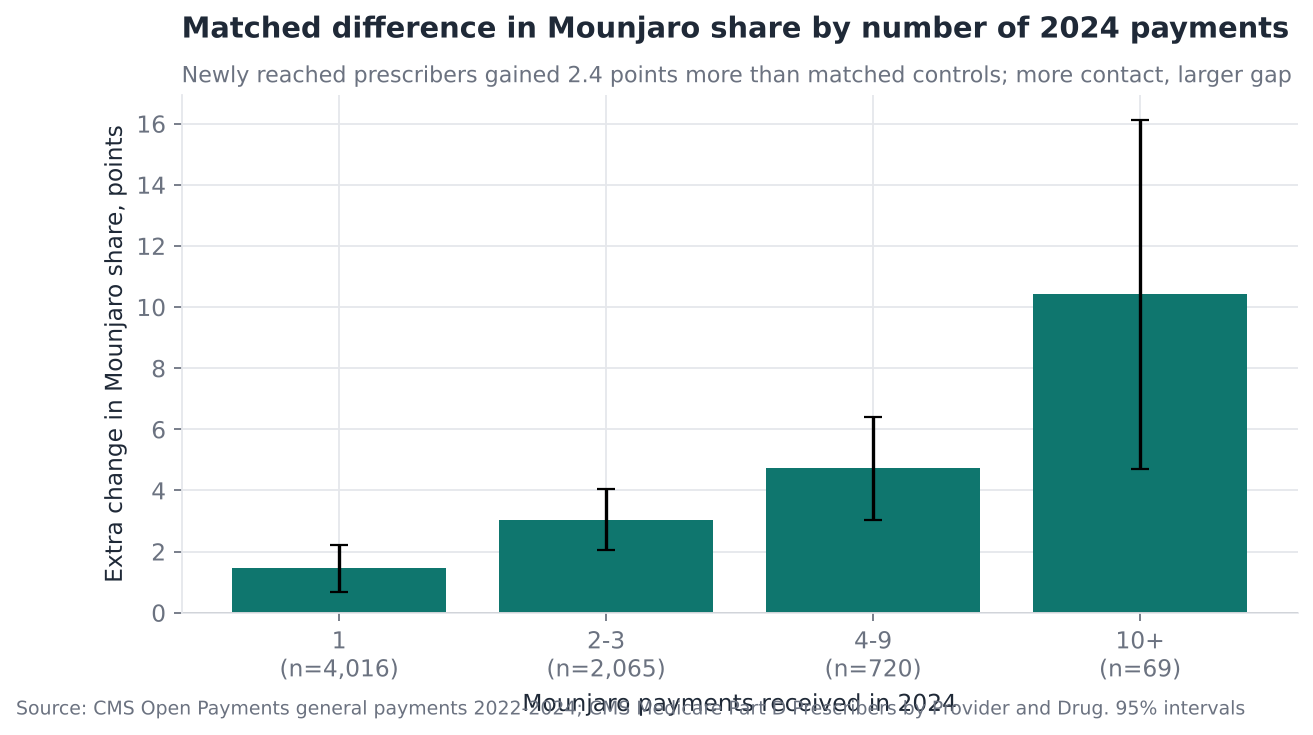

,mean,count,sem
dose,,,
1,0.0145,4016,0.0039
2-3,0.0305,2065,0.0052
4-9,0.0473,720,0.0086
10+,0.1041,69,0.0291


In [8]:
meals24 = mj[mj["year"] == 2024].groupby("npi")["payments"].sum()
tr_m = tr_m.assign(n_pay=tr_m.index.map(meals24).fillna(0), effect=d_mj)
tr_m["dose"] = pd.cut(tr_m["n_pay"], [0, 1, 3, 9, 1e9], labels=["1", "2-3", "4-9", "10+"])
dose = tr_m.groupby("dose", observed=True)["effect"].agg(["mean", "count", "sem"])
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(range(len(dose)), dose["mean"] * 100, yerr=1.96 * dose["sem"] * 100, color=style.ACCENT, capsize=4)
ax.set_xticks(range(len(dose)), [f"{i}\n(n={c:,})" for i, c in zip(dose.index, dose["count"])])
ax.axhline(0, color=style.INK, lw=0.8)
ax.set_xlabel("Mounjaro payments received in 2024")
ax.set_ylabel("Extra change in Mounjaro share, points")
ax.set_title("Matched difference in Mounjaro share by number of 2024 payments")
style.subtitle(ax, f"Newly reached prescribers gained {att['ATT on Mounjaro share (points)']:.1f} points more than matched controls; more contact, larger gap")
style.source(fig, SRC_OP + ". 95% intervals")
style.save(fig, FIG / "04_matched_dose_response.png")
dose.round(4)

**What this does and does not show.** Newly reached prescribers moved
further towards Mounjaro than matched prescribers who were never reached, and
the gap grows with the number of contacts. But the pre-trend check matters:
if the test group was already gaining Mounjaro share before it was reached,
part of the 2024 gap is reps following existing interest rather than causing
it. Matching removes differences that are *measured*; it cannot remove
targeting on things reps know and the data does not (a practice that has just
joined a health plan, say). Treat the estimate as an upper bound on the effect
of a payment, and use a randomised holdout, as in part 6 below, to measure
it properly.

## 5. Multi-channel attribution: which method finds the truth?

From here on the data is simulated, so the true incremental adoptions caused
by each channel are known exactly: re-run the same year without that channel,
using the same random numbers, and count the adoptions lost.

The methods:
- **Last touch / first touch:** all credit to the final / first channel before adoption.
- **Linear:** equal credit to every touch.
- **Markov chain removal effect:** model paths as moves between channels;
  credit each channel by how much the conversion rate falls if it is removed.
- **Shapley value:** split each set of channels' conversions fairly among
  them, from cooperative game theory.

In [9]:
pop = J.population()
opt = pop["email_opt_in"].to_numpy()
rng_ex = np.random.default_rng(3)
X = J.exposure_plan(pop, 52, rng_ex)
adopt, _ = J.run(pop, X)
conv = adopt >= 0
truth = {c: int(conv.sum() - (J.run(pop, X, drop=c)[0] >= 0).sum()) for c in J.CHANNELS}
P = J.paths(X, adopt)
print(f"Adoption: {conv.mean():.1%} of prescribers; promotion adds {sum(truth.values()):,} of {conv.sum():,} adoptions")

credit = {m: dict.fromkeys(J.CHANNELS, 0.0) for m in ["Last touch", "First touch", "Linear"]}
for path, c in zip(P, conv):
    if c and path:
        credit["Last touch"][path[-1]] += 1
        credit["First touch"][path[0]] += 1
        for ch in path:
            credit["Linear"][ch] += 1 / len(path)

# Markov chain (first order): states are channels plus START, CONVERSION and NULL
states = ["START"] + J.CHANNELS + ["CONV", "NULL"]
si = {s: i for i, s in enumerate(states)}
T = np.zeros((len(states), len(states)))
for path, c in zip(P, conv):
    seq = ["START"] + path + (["CONV"] if c else ["NULL"])
    for a, b in zip(seq[:-1], seq[1:]):
        T[si[a], si[b]] += 1
T[si["CONV"], si["CONV"]] = T[si["NULL"], si["NULL"]] = 1


def conv_prob(Tm):
    Pm = Tm / Tm.sum(axis=1, keepdims=True)
    Q = Pm[:-2, :-2]
    R = Pm[:-2, -2:]
    N = np.linalg.solve(np.eye(len(Q)) - Q, R)
    return N[0, 0]


p_all = conv_prob(T)
removal = {}
for ch in J.CHANNELS:
    T2 = T.copy()
    k = si[ch]
    T2[:, si["NULL"]] += T2[:, k]  # sending anyone to the removed channel now ends the path
    T2[:, k] = 0
    T2[k, :] = 0
    T2[k, si["NULL"]] = 1
    removal[ch] = 1 - conv_prob(T2) / p_all
credit["Markov removal"] = {c: removal[c] / sum(removal.values()) for c in J.CHANNELS}

# Shapley value over channel sets (6 channels = 64 coalitions)
sets = pd.Series([frozenset(p) for p in P])
conv_by_set = pd.DataFrame({"s": sets, "c": conv}).groupby("s")["c"].sum()
v = {}
for r in range(len(J.CHANNELS) + 1):
    for S in combinations(J.CHANNELS, r):
        S = frozenset(S)
        v[S] = sum(n for s_, n in conv_by_set.items() if s_ and s_ <= S)
nC = len(J.CHANNELS)
shap = {}
for ch in J.CHANNELS:
    tot = 0.0
    others = [c for c in J.CHANNELS if c != ch]
    for r in range(nC):
        for S in combinations(others, r):
            S = frozenset(S)
            tot += factorial(len(S)) * factorial(nC - len(S) - 1) / factorial(nC) * (v[S | {ch}] - v[S])
    shap[ch] = tot
credit["Shapley"] = shap

att_tab = pd.DataFrame({m: pd.Series(c) / sum(c.values()) for m, c in credit.items()})
att_tab.insert(0, "TRUE share of incremental adoptions", pd.Series(truth) / sum(truth.values()))
att_tab.to_csv(TAB / "attribution_vs_truth.csv")
err = (att_tab.drop(columns=att_tab.columns[0]).sub(att_tab.iloc[:, 0], axis=0)).abs().sum() / 2
att_tab.round(3)

Adoption: 26.7% of prescribers; promotion adds 1,411 of 5,335 adoptions


,TRUE share of incremental adoptions,Last touch,First touch,Linear,Markov removal,Shapley
Rep visit,0.330,0.079,0.116,0.101,0.171,0.168
Rep-triggered email,0.074,0.024,0.000,0.022,0.102,0.063
Brand email,0.380,0.437,0.553,0.468,0.241,0.241
Webinar,0.079,0.089,0.070,0.082,0.171,0.168
Speaker program,0.054,0.031,0.022,0.027,0.085,0.066
Endemic banner,0.083,0.340,0.239,0.300,0.229,0.294


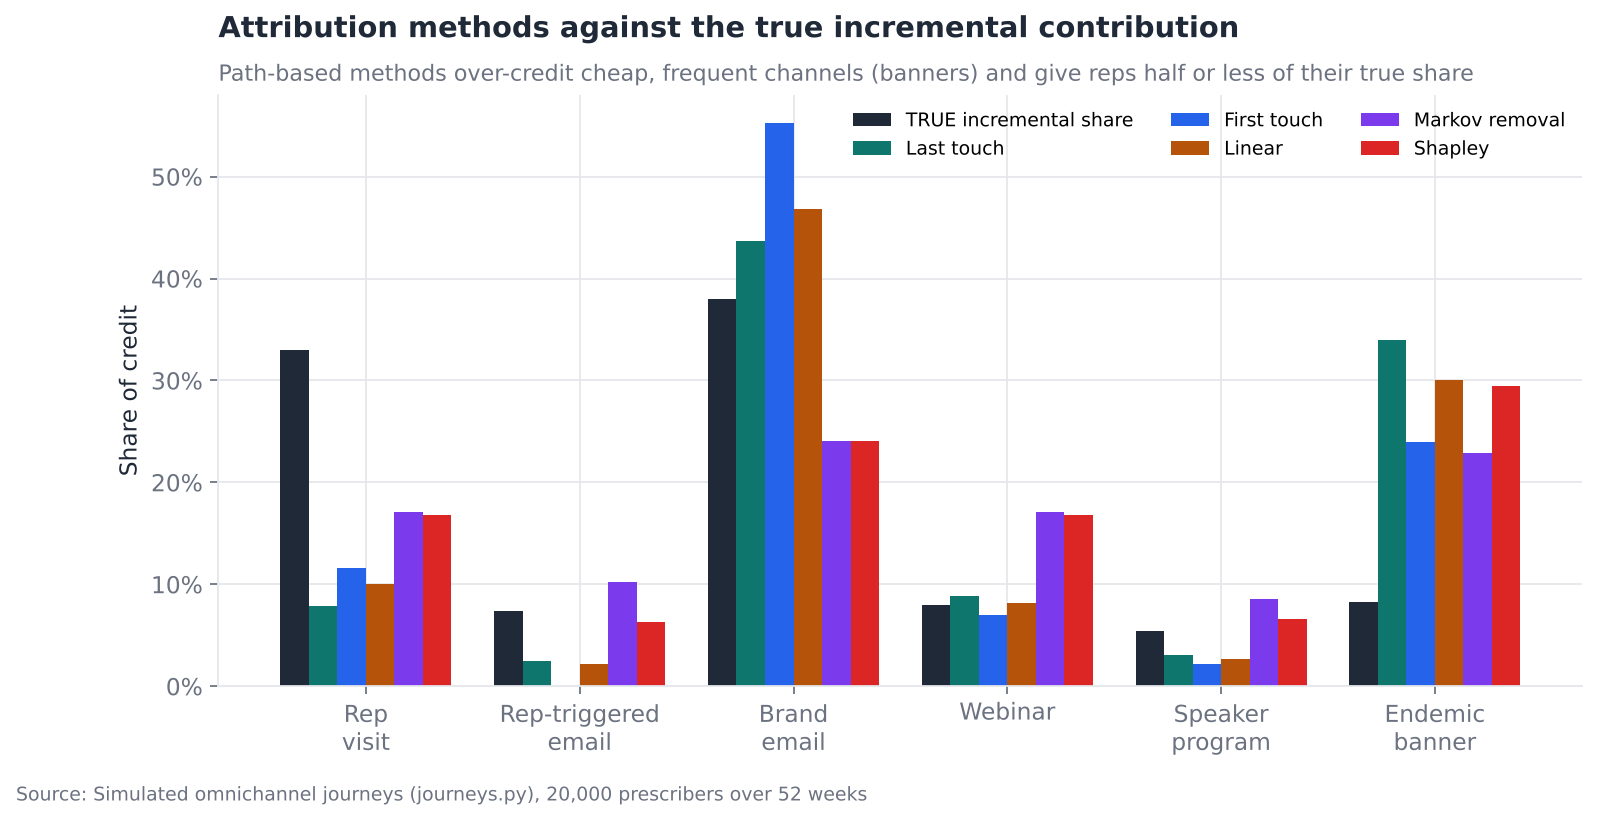

,"total misallocation (0 = perfect, 1 = all wrong)"
Last touch,0.324
First touch,0.329
Linear,0.308
Markov removal,0.298
Shapley,0.312


In [10]:
fig, ax = plt.subplots(figsize=(11, 4.8))
methods = list(att_tab.columns)
xx = np.arange(len(J.CHANNELS))
wid = 0.8 / len(methods)
for i, m in enumerate(methods):
    ax.bar(xx + (i - len(methods) / 2 + 0.5) * wid, att_tab[m], wid,
           color=style.INK if i == 0 else style.PALETTE[(i - 1) % len(style.PALETTE)],
           label=m if i else "TRUE incremental share")
ax.set_xticks(xx, [c.replace(" ", "\n", 1) for c in J.CHANNELS])
style.pct(ax)
ax.set_ylabel("Share of credit")
ax.set_title("Attribution methods against the true incremental contribution")
style.subtitle(ax, "Path-based methods over-credit cheap, frequent channels (banners) and give reps half or less of their true share")
ax.legend(ncol=3, fontsize=8.5)
style.source(fig, SRC_SIM)
style.save(fig, FIG / "05_attribution_vs_truth.png")
err.round(3).rename("total misallocation (0 = perfect, 1 = all wrong)").to_frame()

Banners and brand email touch almost everyone, so they sit on most converting
paths and path-based methods hand them credit for adoptions that would have
happened anyway. Rep visits are rarer but far more persuasive, so every
heuristic under-credits them; a team that cut reps on this evidence would lose
adoptions. Markov and
Shapley are fairer splits of *correlation*, not measures of *causation*.
Attribution is useful for reporting, but budget decisions need experiments or
a causal model.

## 6. Uplift modelling from a randomised holdout

Run a separate, larger experiment (80,000 prescribers) in which half of
opted-in prescribers are randomly held out from brand email for the year.
That turns email into a proper randomised test. An **X-learner** (two
gradient-boosted models, one per group, whose cross-predictions estimate each
prescriber's individual uplift) then predicts *who* email works for, from
what a brand team can observe: digital affinity, open rate, rep access,
decile and specialty. The segments themselves are hidden from the model.

Because this is a simulation, each prescriber's *true* uplift is also known
(the same year run twice, with and without email, with the same luck), so the
targeting can be scored exactly.

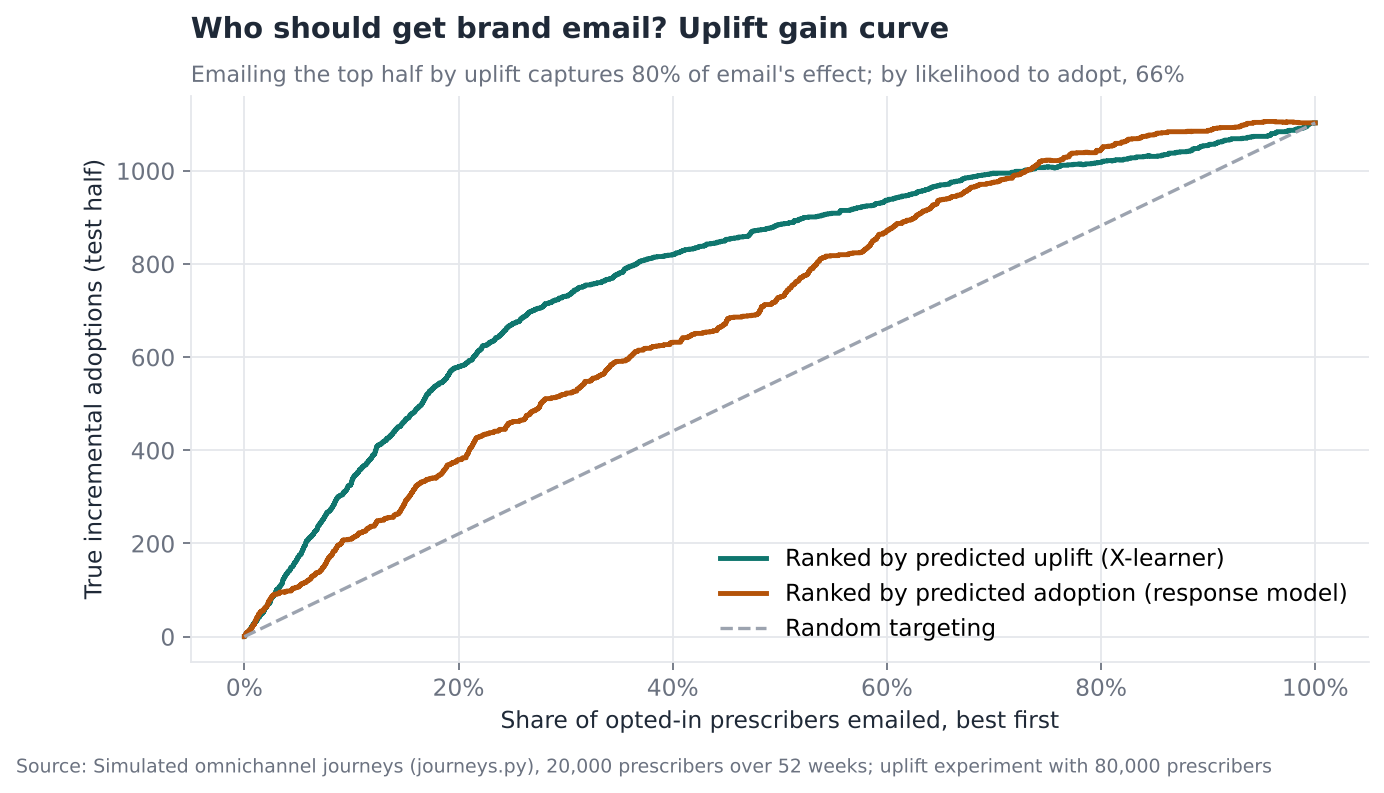

,predicted,true,digital_first
uplift_decile,,,
1,-0.0116,0.0167,0.0090
2,0.0075,0.0129,0.0278
3,0.0204,0.0080,0.0150
4,0.0269,0.0202,0.0264
5,0.0329,0.0181,0.0386
6,0.0389,0.0226,0.0658
7,0.0494,0.0310,0.2066
8,0.0714,0.0529,0.6973
9,0.0928,0.0866,0.9384


In [11]:
pop_u = J.population(80_000, seed=12)
opt_u = pop_u["email_opt_in"].to_numpy()
hold = opt_u & (np.random.default_rng(21).random(len(pop_u)) < 0.5)
Xh = J.exposure_plan(pop_u, 52, np.random.default_rng(22), email_holdout=hold)
ad_h, _ = J.run(pop_u, Xh, rng_seed=23)
df_u = pop_u[opt_u].copy()
df_u["treated"] = (~hold[opt_u]).astype(int)
df_u["y"] = (ad_h[opt_u] >= 0).astype(int)
feat = ["digital_affinity", "email_open_rate", "rep_access", "decile"]
Fx = pd.get_dummies(df_u[feat + ["specialty"]], drop_first=True).astype(float)
train = np.random.default_rng(5).random(len(df_u)) < 0.5
Xtr, Xte = Fx[train], Fx[~train]
ytr, tte = df_u["y"][train], df_u["treated"][train]

gb = dict(max_depth=3, learning_rate=0.05, max_iter=300)
m1 = HistGradientBoostingClassifier(**gb).fit(Xtr[tte == 1], ytr[tte == 1])
m0 = HistGradientBoostingClassifier(**gb).fit(Xtr[tte == 0], ytr[tte == 0])
d1 = ytr[tte == 1] - m0.predict_proba(Xtr[tte == 1])[:, 1]
d0 = m1.predict_proba(Xtr[tte == 0])[:, 1] - ytr[tte == 0]
t1 = HistGradientBoostingRegressor(**gb).fit(Xtr[tte == 1], d1)
t0 = HistGradientBoostingRegressor(**gb).fit(Xtr[tte == 0], d0)
e = 0.5  # share treated (randomised)
uplift_hat = e * t0.predict(Xte) + (1 - e) * t1.predict(Xte)
resp_hat = HistGradientBoostingClassifier(**gb).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

X_on = J.exposure_plan(pop_u, 52, np.random.default_rng(22))
X_off = J.exposure_plan(pop_u, 52, np.random.default_rng(22), email_holdout=opt_u)
true_up = ((J.run(pop_u, X_on, rng_seed=23)[0] >= 0).astype(float) - (J.run(pop_u, X_off, rng_seed=23)[0] >= 0))[opt_u][~train]
te = df_u[~train].assign(uplift_hat=uplift_hat, resp_hat=resp_hat, true_uplift=true_up)


def gain_curve(score):
    d = te.sort_values(score, ascending=False)
    return np.linspace(0, 1, len(d) + 1), np.concatenate([[0], d["true_uplift"].cumsum().to_numpy()])


fig, ax = plt.subplots(figsize=(9.5, 4.6))
for sc, lab, col in [("uplift_hat", "Ranked by predicted uplift (X-learner)", style.ACCENT),
                     ("resp_hat", "Ranked by predicted adoption (response model)", style.ACCENT_2)]:
    fx, gy = gain_curve(sc)
    ax.plot(fx, gy, color=col, lw=2.2, label=lab)
tot = te["true_uplift"].sum()
ax.plot([0, 1], [0, tot], color=style.NEUTRAL, ls="--", label="Random targeting")
style.pct(ax, "x")
ax.set_xlabel("Share of opted-in prescribers emailed, best first")
ax.set_ylabel("True incremental adoptions (test half)")
top_half_u = gain_curve("uplift_hat")[1][len(te) // 2] / tot
top_half_r = gain_curve("resp_hat")[1][len(te) // 2] / tot
ax.set_title("Who should get brand email? Uplift gain curve")
style.subtitle(ax, f"Emailing the top half by uplift captures {top_half_u:.0%} of email's effect; by likelihood to adopt, {top_half_r:.0%}")
ax.legend(loc="lower right")
style.source(fig, SRC_SIM + "; uplift experiment with 80,000 prescribers")
style.save(fig, FIG / "06_uplift_gain.png")

te["uplift_decile"] = pd.qcut(te["uplift_hat"].rank(method="first"), 10, labels=range(1, 11))
dec = te.groupby("uplift_decile", observed=True).agg(predicted=("uplift_hat", "mean"), true=("true_uplift", "mean"),
                                                     digital_first=("segment", lambda s: (s == "Digital-first").mean()))
dec.round(4)

The model was never shown the segments, but its top uplift deciles are made
up mostly of digital-first prescribers, and their true uplift is several times
that of the bottom deciles. Emailing only the top half by predicted uplift
keeps most of email's effect at half the volume, and with it less of the
fatigue that over-emailing causes.

## 7. Email cadence: where fatigue sets in

A designed experiment in the simulation: give opted-in prescribers brand
email at different weekly probabilities (0 to 1 email a week), everything else
unchanged, and measure adoption.

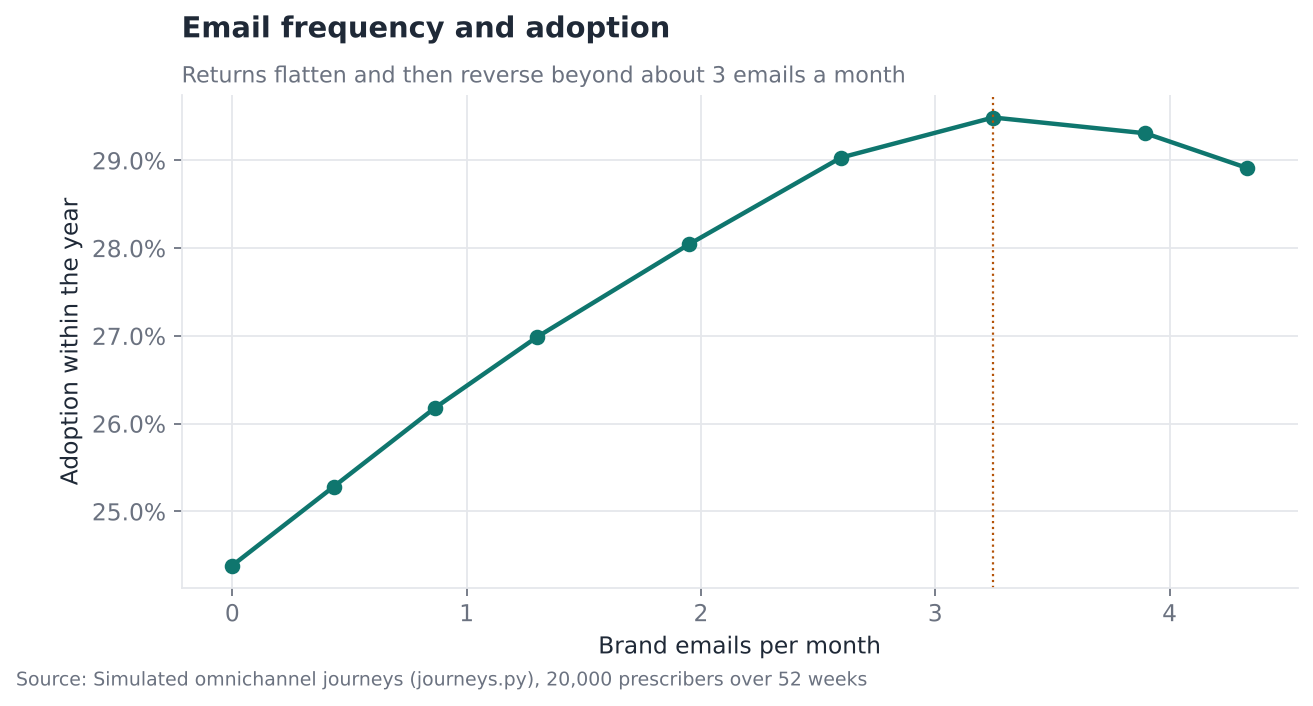

,emails per month,adoption among opted-in
0,0.0000,0.2438
1,0.4330,0.2528
2,0.8660,0.2618
3,1.2990,0.2699
4,1.9485,0.2804
5,2.5980,0.2903
6,3.2475,0.2949
7,3.8970,0.2931
8,4.3300,0.2892


In [12]:
cad = []
base_X = J.exposure_plan(pop, 52, np.random.default_rng(31))
U_mail = np.random.default_rng(32).random(base_X.shape[:2])
for pw in [0, 0.1, 0.2, 0.3, 0.45, 0.6, 0.75, 0.9, 1.0]:
    Xc = base_X.copy()
    Xc[:, :, 2] = (U_mail < pw) * opt[None, :]
    a, _ = J.run(pop, Xc, rng_seed=33)
    cad.append({"emails per month": pw * 4.33, "adoption among opted-in": float((a[opt] >= 0).mean())})
cad = pd.DataFrame(cad)
best = cad.loc[cad["adoption among opted-in"].idxmax()]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cad["emails per month"], cad["adoption among opted-in"], marker="o", color=style.ACCENT, lw=2)
ax.axvline(best["emails per month"], color=style.ACCENT_2, ls=":", lw=1)
style.pct(ax, decimals=1)
ax.set_xlabel("Brand emails per month")
ax.set_ylabel("Adoption within the year")
ax.set_title("Email frequency and adoption")
style.subtitle(ax, f"Returns flatten and then reverse beyond about {best['emails per month']:.0f} emails a month")
style.source(fig, SRC_SIM)
style.save(fig, FIG / "07_email_cadence.png")
cad.round(4)

## 8. Next best channel: a learning policy against fixed rules

Each week, for every prescriber who has not adopted, choose one action:
nothing, brand email, a digital banner, a webinar invitation or a rep visit.
Each action has a cost; an adoption is worth $25,000 of first-year revenue
(illustrative). Four policies run on the same prescribers for 26 weeks:

- **Fixed rules:** reps for the top three deciles every third week, email for
  other opted-in prescribers, banners for the rest. A typical business-rules plan.
- **Random:** a random action each week (a floor).
- **Thompson sampling on nine segments:** prescribers are grouped into nine
  contexts by observable digital affinity and decile. For each context and
  action it keeps a probability distribution for the weekly adoption rate, draws
  from it, picks the action with the best sampled net value, and updates.
- **Contextual bandit with gradient boosting:** four weeks of randomised
  actions, then one gradient-boosted model per action predicts each
  prescriber's chance of adopting in the next three weeks from their observable
  profile. It picks the action with the best *incremental* value over doing
  nothing, keeps 5% of choices random so it keeps learning, and refits every
  three weeks. Both learning policies start knowing nothing.
- **Oracle:** knows every prescriber's true response and picks the best
  expected action each week. No real policy can do better; it is the ceiling.

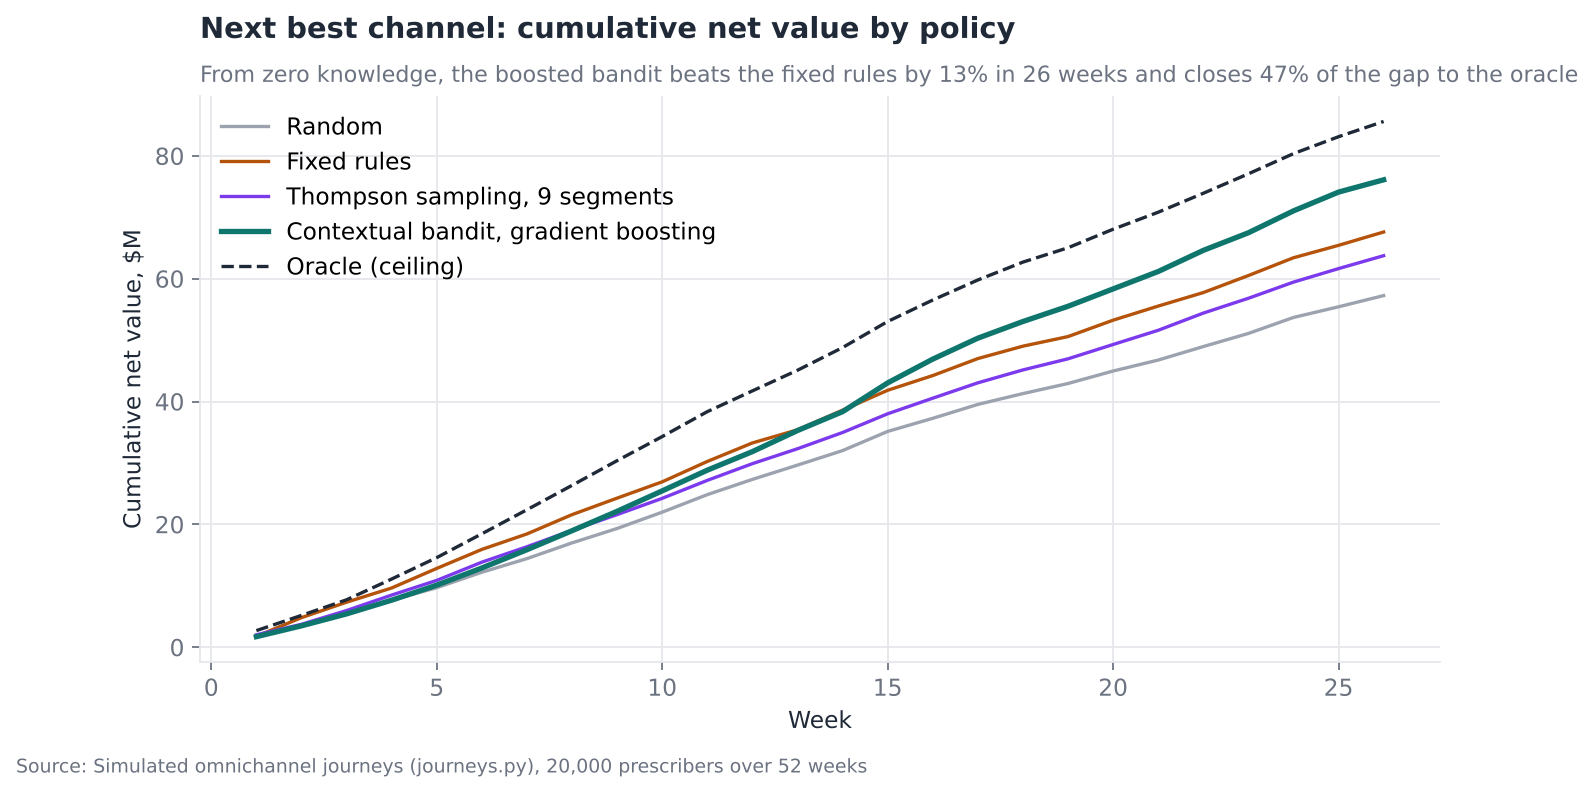

(                                 policy  adoptions  cost ($M)  net value ($M)
 0                                Random       3426      28.40           57.25
 1                           Fixed rules       3228      13.10           67.60
 2         Thompson sampling, 9 segments       2946       9.90           63.75
 3  Contextual bandit, gradient boosting       4732      42.20           76.10
 4                      Oracle (ceiling)       4099      16.87           85.60,
                 Fixed rules  Thompson sampling, 9 segments  \
 Brand email           0.650                          0.258   
 Endemic banner        0.252                          0.327   
 Rep visit             0.098                          0.042   
 Webinar               0.000                          0.188   
 None                  0.000                          0.185   
 
                 Contextual bandit, gradient boosting  
 Brand email                                    0.140  
 Endemic banner                  

In [13]:
ACTIONS = ["None", "Brand email", "Endemic banner", "Webinar", "Rep visit"]
ACOST = np.array([0, J.COST["Brand email"], J.COST["Endemic banner"], J.COST["Webinar"], J.COST["Rep visit"]])
A2C = [None, 2, 5, 3, 0]
eff, dz = J.segment_effects(pop)
ctx = (pd.qcut(pop["digital_affinity"], 3, labels=False).to_numpy() * 3 + np.digitize(pop["decile"], [4, 8])).astype(int)
WEEKS_B = 26


FEATS = pop[["digital_affinity", "email_open_rate", "rep_access", "decile"]].assign(opt=opt.astype(float)).to_numpy()


def simulate_policy(kind: str, seed: int = 41, explore: int = 4, eps: float = 0.05, horizon: int = 3, refit: int = 3):
    rng = np.random.default_rng(seed)
    U = np.random.default_rng(99).random((WEEKS_B, len(pop)))  # same luck for every policy
    stock = np.zeros((len(pop), len(J.CHANNELS)))
    mails = np.zeros((WEEKS_B, len(pop)))
    alive = np.ones(len(pop), bool)
    adopt_week = np.full(len(pop), 10 ** 6)
    a_post, b_post = np.ones((9, len(ACTIONS))), np.full((9, len(ACTIONS)), 50.0)
    log, models = [], None
    cost = adopted = 0
    curve = []
    for t in range(WEEKS_B):
        decay_stock = stock * J.DECAY
        recent = mails[max(0, t - 3): t].sum(axis=0)
        if kind == "rules":
            act = np.where((pop["decile"].to_numpy() >= 8) & (t % 3 == 0), 4, np.where(opt, 1, 2))
        elif kind == "random":
            act = rng.integers(0, len(ACTIONS), len(pop))
        elif kind == "thompson":
            draw = rng.beta(a_post[ctx], b_post[ctx])
            act = np.argmax(draw * J.VALUE_PER_ADOPTION - ACOST[None, :], axis=1)
        elif kind == "boosted":
            if t >= explore and (models is None or (t - explore) % refit == 0):
                L = [r for r in log if r[0] + horizon <= t]
                tt = np.concatenate([np.full(len(r[1]), r[0]) for r in L])
                ii = np.concatenate([r[1] for r in L])
                aa = np.concatenate([r[2] for r in L])
                y = (adopt_week[ii] >= tt) & (adopt_week[ii] < tt + horizon)
                models = [HistGradientBoostingClassifier(max_depth=3, max_iter=150, learning_rate=0.08).fit(FEATS[ii[aa == a]], y[aa == a])
                          for a in range(len(ACTIONS))]
            if models is None:
                act = rng.integers(0, len(ACTIONS), len(pop))
            else:
                Pm = np.column_stack([m.predict_proba(FEATS)[:, 1] for m in models])
                gain = (Pm - Pm[:, [0]]) * J.VALUE_PER_ADOPTION - ACOST[None, :]
                gain[~opt, 1] = -np.inf
                act = np.argmax(gain, axis=1)
                ex = rng.random(len(pop)) < eps
                act[ex] = rng.integers(0, len(ACTIONS), ex.sum())
        else:  # oracle: true response, myopic
            best = np.full(len(pop), -np.inf)
            act = np.zeros(len(pop), int)
            for ai, ci in enumerate(A2C):
                s2 = decay_stock.copy()
                if ci is not None:
                    s2[:, ci] += 1
                gain = J.hazard(s2, recent + (1 if ci == 2 else 0), eff, dz) * J.VALUE_PER_ADOPTION - ACOST[ai]
                if ai == 1:
                    gain = np.where(opt, gain, -np.inf)
                upd = gain > best
                best[upd], act[upd] = gain[upd], ai
        act = np.where((act == 1) & ~opt, 2, act)  # cannot email prescribers who have not opted in
        act = np.where(alive, act, 0)
        Xw = np.zeros_like(stock)
        for ai, ci in enumerate(A2C):
            if ci is not None:
                Xw[act == ai, ci] = 1
        stock = decay_stock + Xw
        mails[t] = Xw[:, 2]
        h = J.hazard(stock, mails[max(0, t - 3): t + 1].sum(axis=0), eff, dz)
        new = alive & (U[t] < h)
        adopt_week[new] = t
        if kind == "thompson":
            for ai in range(len(ACTIONS)):
                sel = alive & (act == ai)
                np.add.at(a_post[:, ai], ctx[sel], new[sel])
                np.add.at(b_post[:, ai], ctx[sel], (~new[sel]).astype(float))
        idx = np.nonzero(alive)[0]
        log.append((t, idx, act[idx]))
        cost += ACOST[act[alive]].sum()
        adopted += new.sum()
        alive &= ~new
        curve.append(adopted * J.VALUE_PER_ADOPTION - cost)
    return {"policy": kind, "adoptions": int(adopted), "cost ($M)": cost / 1e6,
            "net value ($M)": (adopted * J.VALUE_PER_ADOPTION - cost) / 1e6, "curve": curve,
            "action mix": pd.Series(np.concatenate([r[2] for r in log])).map(dict(enumerate(ACTIONS))).value_counts(normalize=True).round(3).to_dict()}


runs = [simulate_policy(k) for k in ["random", "rules", "thompson", "boosted", "oracle"]]
names = {"random": "Random", "rules": "Fixed rules", "thompson": "Thompson sampling, 9 segments",
         "boosted": "Contextual bandit, gradient boosting", "oracle": "Oracle (ceiling)"}
fig, ax = plt.subplots(figsize=(10, 4.6))
for r, col in zip(runs, [style.NEUTRAL, style.ACCENT_2, style.PALETTE[3], style.ACCENT, style.INK]):
    ax.plot(np.arange(1, WEEKS_B + 1), np.array(r["curve"]) / 1e6, color=col, lw=2.4 if r["policy"] == "boosted" else 1.5,
            ls="--" if r["policy"] == "oracle" else "-", label=names[r["policy"]])
ax.set_xlabel("Week")
ax.set_ylabel("Cumulative net value, $M")
ax.set_title("Next best channel: cumulative net value by policy")
rules_v = runs[1]["net value ($M)"]
ts_v = runs[3]["net value ($M)"]
orc_v = runs[4]["net value ($M)"]
style.subtitle(ax, f"From zero knowledge, the boosted bandit beats the fixed rules by {ts_v / rules_v - 1:.0%} in 26 weeks "
               f"and closes {(ts_v - rules_v) / (orc_v - rules_v):.0%} of the gap to the oracle")
ax.legend(loc="upper left")
style.source(fig, SRC_SIM)
style.save(fig, FIG / "08_bandit_policies.png")
bandit = pd.DataFrame([{k: v for k, v in r.items() if k not in ("curve", "action mix")} for r in runs]).assign(policy=lambda d: d["policy"].map(names))
mix = pd.DataFrame({names[r["policy"]]: r["action mix"] for r in runs[1:4]}).fillna(0)
display_tables = (bandit.round(2), mix)
display_tables

Two lessons. First, the coarse Thompson sampler loses to the fixed rules: with
only nine segments, the small *extra* effect of each action is buried in
baseline adoption, so it mostly learns which segments adopt anyway. Second,
the boosted bandit wins because it estimates the *increment* over doing
nothing for each prescriber's own profile. It spends more than the rules plan
(more webinars and banners for digital-leaning prescribers, reps only where
rep access is high) and earns it back in extra adoptions. The oracle shows how
much is still left once the bandit has more data.

## 9. Summary

In [14]:
summary = {
    "payments_2024": int(y24["payments"].sum()), "dollars_2024_musd": round(float(y24["amount"].sum() / 1e6), 1),
    "hcps_reached_2024": int(y24["npi"].nunique()),
    "meal_share_of_payments_2024": round(float(nature.loc["Food and Beverage", "share of payments"]), 3),
    "speaker_share_of_dollars_2024": round(float(nature.loc["Speaker fees", "share of dollars"]), 3),
    "top_decile_reach": {"Novo": round(float(reach.loc[10, "Novo reach"]), 3), "Lilly": round(float(reach.loc[10, "Lilly reach"]), 3)},
    "bottom_half_reach_any": round(float(((vol["decile"] <= 5) & ((vol["Novo Nordisk payments"] > 0) | (vol["Lilly payments"] > 0))).sum() / (vol["decile"] <= 5).sum()), 3),
    "lilly_sov_minus_som_median_state": round(sov_gap, 3),
    "psm_matched_pairs": att["matched pairs"], "psm_max_abs_smd_after": round(float(bal["after matching"].abs().max()), 3),
    "psm_max_abs_smd_before": round(float(bal["before matching"].abs().max()), 3), "psm_att_points": round(att["ATT on Mounjaro share (points)"], 2),
    "psm_att_ci": [round(att["95% CI low"], 2), round(att["95% CI high"], 2)],
    "psm_pretrend_points": round(att["pre-trend 2022-23 (points)"], 2),
    "attribution_misallocation": err.round(3).to_dict(),
    "uplift_top_decile_true": round(float(dec["true"].iloc[-1]), 4), "uplift_bottom_decile_true": round(float(dec["true"].iloc[0]), 4),
    "uplift_top_half_capture": round(float(top_half_u), 3), "response_top_half_capture": round(float(top_half_r), 3),
    "email_optimal_per_month": round(float(best["emails per month"]), 1),
    "bandit_net_value_musd": dict(zip(bandit["policy"], bandit["net value ($M)"].round(2))),
}
pd.Series(summary).to_json(TAB / "summary.json", indent=1)
summary

{'payments_2024': 1105279,
 'dollars_2024_musd': 54.4,
 'hcps_reached_2024': 154019,
 'meal_share_of_payments_2024': 0.971,
 'speaker_share_of_dollars_2024': 0.513,
 'top_decile_reach': {'Novo': 0.57, 'Lilly': 0.494},
 'bottom_half_reach_any': 0.277,
 'lilly_sov_minus_som_median_state': -0.048,
 'psm_matched_pairs': 6870,
 'psm_max_abs_smd_after': 0.087,
 'psm_max_abs_smd_before': 0.933,
 'psm_att_points': 2.37,
 'psm_att_ci': [1.78, 2.93],
 'psm_pretrend_points': 0.59,
 'attribution_misallocation': {'Last touch': 0.324,
  'First touch': 0.329,
  'Linear': 0.308,
  'Markov removal': 0.298,
  'Shapley': 0.312},
 'uplift_top_decile_true': 0.1148,
 'uplift_bottom_decile_true': 0.0167,
 'uplift_top_half_capture': 0.802,
 'response_top_half_capture': 0.66,
 'email_optimal_per_month': 3.2,
 'bandit_net_value_musd': {'Random': 57.25,
  'Fixed rules': 67.6,
  'Thompson sampling, 9 segments': 63.75,
  'Contextual bandit, gradient boosting': 76.1,
  'Oracle (ceiling)': 85.6}}